# Training loop

Training loop là đoạn code lặp lại các bước: lấy một batch, tính dự đoán, tính loss, tính gradient, cập nhật trọng số. Viết cho loss giảm thì dễ; khó hơn là để kết quả dùng lại được. Các lỗi hay gặp: quên lưu mean/std dùng để chuẩn hóa, quên chuyển model sang chế độ eval nên dropout vẫn bật lúc dự đoán, chỉ lưu trọng số mà không lưu cấu hình model. Bài này viết một training loop đầy đủ, từ đọc dữ liệu tới lưu checkpoint, rồi nạp lại trong một chương trình mới và kiểm rằng dự đoán không đổi.

> **Mục tiêu**
>
> - Dùng Dataset, DataLoader; phân biệt batch, step, epoch.
> - Viết training loop đúng thứ tự các bước.
> - Chấm validation và lưu checkpoint tốt nhất.
> - Nạp lại model trong chương trình mới và kiểm kết quả.

## Một bài nhỏ để kiểm toàn bộ quy trình

Ta tự sinh 96 điểm hai đặc trưng; nhãn là 1 nếu $x_1+0.5x_2>0$, còn lại là 0. Quy tắc đã biết trước, nên nếu kết quả tệ thì lỗi nằm ở pipeline chứ không phải ở độ khó của dữ liệu. Chia train/validation trước; mean/std chỉ tính trên train và được dùng lại trên validation.

In [ ]:
from pathlib import Path
import json
import subprocess
import sys
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

torch.set_num_threads(1)
torch.manual_seed(21)
torch.use_deterministic_algorithms(True)
generator = torch.Generator().manual_seed(21)
raw_X = torch.randn(96, 2, generator=generator)
y = (raw_X[:, 0] + .5 * raw_X[:, 1] > 0).long()
order = torch.randperm(96, generator=generator)
train_id, valid_id = order[:72], order[72:]
mean = raw_X[train_id].mean(dim=0)
scale = raw_X[train_id].std(dim=0, unbiased=False).clamp_min(1e-6)
X = (raw_X - mean) / scale
train_data = TensorDataset(X[train_id], y[train_id])
valid_data = TensorDataset(X[valid_id], y[valid_id])
train_loader = DataLoader(train_data, batch_size=16, shuffle=True,
    generator=torch.Generator().manual_seed(21), num_workers=0)
valid_loader = DataLoader(valid_data, batch_size=16, shuffle=False, num_workers=0)
print(len(train_data), len(valid_data), len(train_loader))
print(tuple(next(iter(valid_loader))[0].shape))

72 24 5
(16, 2)


Có 72 mẫu train, 24 validation và 5 batch mỗi epoch: bốn batch 16 mẫu, một batch 8 mẫu. Ba từ cần phân biệt:

- **Batch**: một nhóm mẫu dùng cho một lần tính gradient.
- **Step**: một lần optimizer cập nhật trọng số; mỗi batch một step.
- **Epoch**: một lần duyệt hết tập train.

Một epoch có $\lceil n/B \rceil$ step: 10 000 ảnh với batch 64 là 157 step; 1000 mẫu, batch 32, 5 epoch là $32 \cdot 5 = 160$ lần cập nhật.

`TensorDataset` gom các tensor cùng chiều đầu; dataset thực tế có thể tự đọc tệp ở `__getitem__` (mục cuối bài). DataLoader ghép các mẫu thành batch và quyết định thứ tự lấy. Với `shuffle=True`, thứ tự được xáo lại ở đầu mỗi epoch. Nếu tập train xếp sẵn hết mèo rồi mới tới chó mà không xáo, mỗi đoạn batch chỉ thấy một lớp, và mô hình bị kéo qua lại giữa hai lớp.



Ở Windows, nhiều worker có thể tạo tiến trình con và yêu cầu bảo vệ code bằng `if __name__ == '__main__'`. Ví dụ đầu tiên dùng `num_workers=0` để dễ chạy nối tiếp trong notebook. Việc tăng worker nên dựa trên đo nút nghẽn, không phải mặc định “càng nhiều càng nhanh”.

**Hỏi nhanh.** Train có 72 mẫu, batch size 16, không bỏ batch cuối. Train 20 epoch thì optimizer cập nhật bao nhiêu lần?

- A. 20
- B. 80
- C. 100
- D. 1440

<details><summary>Đáp án</summary>

C. 100

Mỗi epoch có $\lceil 72/16\rceil = 5$ batch, mỗi batch một bước, nên 20 epoch là 100 bước. Ra 20 là nhầm epoch với bước. Ra 80 là quên batch cuối có 8 mẫu, mà batch ấy vẫn là một lần cập nhật. Ra 1440 là đếm theo mẫu, chỉ đúng khi batch size bằng 1.

</details>

## Loop là một chu trình trạng thái

Mỗi batch đi qua năm bước theo đúng thứ tự:

1. `zero_grad` xóa gradient cũ.
2. Forward dùng trọng số hiện tại để tạo logits.
3. Loss so logits với nhãn.
4. Backward tính gradient.
5. Step sửa trọng số.

Đảo step lên trước backward thì optimizer dùng gradient cũ hoặc không có gradient. Gọi zero_grad sau backward, trước step, thì xóa chính tín hiệu vừa tính. Nếu cần cắt gradient bằng `clip_grad_norm_`, đặt nó sau backward và trước step.

Optimizer được tạo từ `model.parameters()`, tức các trọng số và bias sẽ được chỉnh; nó quyết định chỉnh theo cách nào (SGD, Adam ở bài 3.5).



Vì sao phải xóa? Backward không ghi đè `.grad` mà **cộng** gradient mới vào đó. Với hàm $\mathbf{x}^\top\mathbf{w}$, gradient theo $\mathbf{w}$ chính là $\mathbf{x}$, nên dễ nhìn thấy điều này:

In [ ]:
w = torch.zeros(2, requires_grad=True)
for xi in [torch.tensor([1., 2.]), torch.tensor([3., -1.])]:
    (xi @ w).backward()
    print(w.grad.tolist())

[1.0, 2.0]
[4.0, 1.0]


Lần thứ hai `.grad` là $[1,2]+[3,-1]=[4,1]$, không phải $[3,-1]$. Thiếu `zero_grad`, mỗi step dùng tổng gradient của mọi batch đã qua, nên bước cập nhật lớn dần. Cộng dồn có chủ ý lại là một kỹ thuật: gradient accumulation (bài 3.7) gom gradient vài batch nhỏ rồi mới step một lần.

**Hỏi nhanh.** Một vòng lặp gọi `loss.backward()`, rồi `optimizer.zero_grad(set_to_none=True)`, rồi `optimizer.step()`. Train loss đứng yên ở mức ban đầu qua mọi epoch, và không có lỗi nào. Vì sao?

- A. Learning rate quá nhỏ nên mỗi bước gần như không đổi gì
- B. Gradient bị xóa trước `step()`, nên không có gì để cập nhật
- C. Gradient cộng dồn qua các batch nên các bước triệt tiêu nhau
- D. Backward chưa chạy xong vì `zero_grad` được gọi ngay sau nó

<details><summary>Đáp án</summary>

B. Gradient bị xóa trước `step()`, nên không có gì để cập nhật

`set_to_none=True` đặt `.grad` thành `None`, và optimizer bỏ qua tham số không có gradient. Trọng số giữ nguyên giá trị khởi tạo, nên loss đứng yên. Learning rate nhỏ thì loss giảm chậm, chứ không đứng yên tuyệt đối. `zero_grad` có được gọi, nên gradient không cộng dồn. Backward chạy xong trước khi lệnh tiếp theo bắt đầu: `.grad` đã được tính đủ, rồi mới bị xóa.

</details>

Model có hai lớp linear xen ReLU. Loss nhận logits `(B,2)` và nhãn long `(B,)`. Ta gom code train một epoch thành một hàm. Loss báo cáo nhân batch size trước khi cộng, để batch cuối nhỏ không được tính ngang trọng lượng với batch đầy:

In [ ]:
def make_model():
    return nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 2))

model = make_model()
optimizer = torch.optim.Adam(model.parameters(), lr=.03)
criterion = nn.CrossEntropyLoss()

def train_epoch(model, loader, optimizer):
    model.train()
    loss_sum = 0.
    seen = 0
    for xb, yb in loader:
        optimizer.zero_grad(set_to_none=True)
        logits = model(xb)
        assert logits.shape == (len(yb), 2)
        loss = criterion(logits, yb)
        assert torch.isfinite(loss)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * len(yb)
        seen += len(yb)
    return loss_sum / seen

def evaluate(model, loader):
    model.eval()
    loss_sum = 0.
    correct = 0
    seen = 0
    with torch.no_grad():
        for xb, yb in loader:
            logits = model(xb)
            loss_sum += criterion(logits, yb).item() * len(yb)
            correct += (logits.argmax(dim=1) == yb).sum().item()
            seen += len(yb)
    return loss_sum / seen, correct / seen

print('initial validation:', tuple(round(v, 4) for v in evaluate(model, valid_loader)))

initial validation: (0.7394, 0.4583)


Trước khi học, accuracy $0.4583=11/24$, gần mức đoán bừa của hai lớp, và loss $0.7394$ gần $\ln 2\approx0.693$, loss của một model chia đều xác suất cho hai lớp. Đó là điểm xuất phát đúng. Với $K$ lớp, loss ban đầu lệch xa $\ln K$ là dấu hiệu nên kiểm khởi tạo hoặc nhãn trước khi train.

Hai `assert` trong `train_epoch` là hai phép kiểm rẻ: logits đúng shape `(B,2)` và loss hữu hạn. Loss thành `nan` thường do learning rate quá lớn làm trọng số phân kỳ, hoặc do phép `log`, phép chia không an toàn trong loss tự viết; assert dừng loop ngay ở batch đầu tiên gặp lỗi, trước khi `nan` lan vào trọng số.

`model.train()` và `model.eval()` điều khiển hành vi của các layer như dropout, BatchNorm (bài 3.6). `no_grad()` điều khiển việc ghi graph. Eval không tự tắt gradient; no_grad không tự tắt dropout. Mạng nhỏ này chưa có hai layer đó, nhưng vẫn giữ hai lời gọi để loop dùng được khi kiến trúc thay đổi.

Training loss trong hàm là trung bình loss quan sát **trong khi trọng số thay đổi** qua các batch. Nó không nhất thiết bằng loss đánh giá lại toàn bộ train ở checkpoint cuối epoch. Nếu cần so train/validation chặt chẽ, gọi cùng `evaluate` trên cả hai loader sau epoch, dùng cùng chế độ layer.

**Hỏi nhanh.** Model có lớp Dropout, tức lớp tắt ngẫu nhiên một số nơ-ron trong lúc train (bài 3.6 sẽ học kỹ). Hàm chấm validation có `with torch.no_grad():` nhưng quên `model.eval()`. Chuyện gì xảy ra?

- A. Dropout vẫn tắt ngẫu nhiên nơ-ron, nên điểm dao động
- B. `no_grad` tự chuyển model sang eval, nên vẫn đúng
- C. Graph vẫn được ghi lại, vì model còn ở chế độ train
- D. Báo lỗi, vì Dropout cần gradient mới chạy được

<details><summary>Đáp án</summary>

A. Dropout vẫn tắt ngẫu nhiên nơ-ron, nên điểm dao động

`no_grad` chỉ ngừng ghi graph. Còn các lớp hoạt động thế nào là do `train()` hay `eval()` quyết định. Dropout vẫn chạy như lúc train, nên chấm hai lần cùng một model cho hai điểm khác nhau, thường thấp hơn thật. Ở trong `no_grad` thì chế độ train không làm graph được ghi. Dropout chạy bình thường mà không cần gradient.

</details>

Cộng loss qua các batch cũng phải tính theo mẫu. Giả sử batch đầu có 16 mẫu, loss mean 0.2; batch cuối có 8 mẫu, loss mean 0.8. Trung bình hai số bằng 0.5, nhưng trung bình theo 24 mẫu là $(16\cdot0.2+8\cdot0.8)/24=0.4$. Đó là lý do code nhân `len(yb)` trước khi cộng.

Cách này đúng với cross-entropy không trọng số của bài. Khi dùng class weight, `ignore_index` hoặc loss trung bình theo pixel, mẫu số đúng là tổng trọng số hoặc số phần tử thật sự được tính, nên cần đọc `reduction` của loss trước khi cộng. `CrossEntropyLoss` mặc định bỏ qua nhãn $-100$ (`ignore_index`) và chia cho số nhãn còn lại. Đổi `reduction='mean'` sang `'sum'` với batch 64 mà giữ learning rate của SGD là nhân bước đi lên 64 lần.



**Hỏi nhanh.** Một epoch có bốn batch 16 mẫu, batch nào cũng có loss trung bình 0.1, và một batch cuối 8 mẫu có loss trung bình 0.7. Loss trung bình theo mẫu của cả epoch là bao nhiêu?

- A. 0.10
- B. 0.17
- C. 0.22
- D. 0.40

<details><summary>Đáp án</summary>

B. 0.17

$(64\cdot 0.1 + 8\cdot 0.7)/72 = 12/72 \approx 0.17$. Ra 0.22 là lấy trung bình đều năm batch, coi batch 8 mẫu nặng ngang batch 16 mẫu. Ra 0.40 là trung bình của hai mức loss. Ra 0.10 là bỏ batch cuối, như khi đặt `drop_last=True`.

</details>

## Chọn checkpoint theo validation

Nếu chỉ lưu epoch cuối, ta có thể bỏ mất model đã tổng quát hóa tốt hơn ở giữa quá trình. Ta chọn loss validation nhỏ nhất; metric lựa chọn trong bài thật có thể là F1, RMSE hoặc metric của scorer. Chốt hướng “nhỏ hơn tốt” hay “lớn hơn tốt” trước khi viết điều kiện so sánh.

Lưu bản tốt nhất phải lưu bản sao. Các tensor trong `model.state_dict()` dùng chung bộ nhớ với tham số; chỉ gán `best_state = model.state_dict()` rồi tiếp tục học thì “bản tốt nhất” đổi theo model. Dùng clone hoặc deepcopy, hoặc ghi tệp ngay khi gặp bản tốt hơn.

In [ ]:
best_loss = float('inf')
best_epoch = -1
best_state = None
history = []
for epoch in range(35):
    training_loss = train_epoch(model, train_loader, optimizer)
    valid_loss, valid_accuracy = evaluate(model, valid_loader)
    history.append((epoch + 1, training_loss, valid_loss, valid_accuracy))
    if valid_loss < best_loss:
        best_loss = valid_loss
        best_epoch = epoch + 1
        best_state = {name: value.detach().cpu().clone()
                      for name, value in model.state_dict().items()}
    if epoch in [0, 9, 19, 34]:
        print(epoch + 1, round(training_loss, 4),
              round(valid_loss, 4), round(valid_accuracy, 4))

perfect = [e for e, _, _, accuracy in history if accuracy == 1.0]
print('accuracy 1.0:', len(perfect), 'epochs, first', perfect[0])
model.load_state_dict(best_state)
model.eval()
print('best epoch:', best_epoch)
print('best validation:', tuple(round(v, 4) for v in evaluate(model, valid_loader)))

1 0.6312 0.6167 0.625
10 0.0687 0.0751 0.9583
20 0.039 0.0396 1.0
35 0.0197 0.0429 1.0
accuracy 1.0: 21 epochs, first 7
best epoch: 32
best validation: (0.03, 1.0)


Mỗi dòng epoch có train loss, validation loss và validation accuracy. Train loss giảm gần như đều từ 0.6312 xuống 0.0197, còn validation loss thấp nhất ở epoch 32 (0.03) rồi lên 0.0429 ở epoch 35: epoch cuối không phải epoch tốt nhất.

Validation chỉ 24 mẫu nên accuracy đi theo nấc $1/24$; 21 trong 35 epoch cùng đạt 1.0, accuracy không phân biệt được chúng, còn loss thì phân biệt được. Điểm `(0.03, 1.0)` đã được dùng để chọn epoch, nên nó hơi lạc quan so với dữ liệu mới.



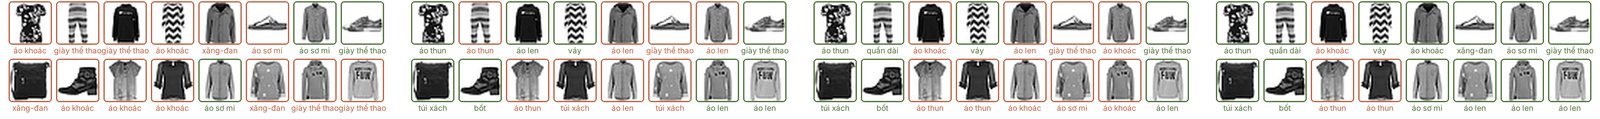

**Hỏi nhanh.** Code chọn checkpoint ghi `best_state = model.state_dict()`, không clone, mỗi khi validation loss tốt hơn. Train hết 35 epoch rồi `model.load_state_dict(best_state)`. Model có trọng số của epoch nào?

- A. Epoch 32, epoch có validation loss nhỏ nhất
- B. Epoch 1, lần đầu điều kiện được thỏa
- C. Không xác định, vì tensor cũ đã bị giải phóng
- D. Epoch 35, vì `best_state` thay đổi theo model

<details><summary>Đáp án</summary>

D. Epoch 35, vì `best_state` thay đổi theo model

`state_dict()` trả về một dictionary mới, nhưng các tensor bên trong dùng chung bộ nhớ với tham số. Optimizer sửa tham số tại chỗ, nên `best_state` luôn phản ánh trọng số hiện tại, tức epoch 35. Muốn giữ được epoch 32 thì phải lưu bản sao như code của bài. Tensor không bị giải phóng, vì `best_state` vẫn còn tham chiếu tới chúng.

</details>

**Hỏi nhanh.** Giả sử vòng lặp trên chọn checkpoint theo validation accuracy, với điều kiện `valid_accuracy > best_accuracy` và `best_accuracy` khởi tạo bằng 0, thay vì theo loss. Checkpoint là epoch nào?

- A. Epoch 7, lần đầu accuracy đạt 1.0
- B. Epoch 20, mốc log đầu tiên có accuracy 1.0
- C. Epoch 32, cũng là epoch có loss nhỏ nhất
- D. Epoch 35, lần cuối accuracy đạt 1.0

<details><summary>Đáp án</summary>

A. Epoch 7, lần đầu accuracy đạt 1.0

Dấu `>` chỉ cập nhật khi tốt hơn hẳn. Từ epoch 7 trở đi không epoch nào vượt được 1.0, nên checkpoint dừng ở đó. Bốn dòng log chỉ là bốn mốc được in ra, không phải mọi epoch. Dùng `>=` thì sẽ giữ epoch 35. Khi metric chỉ có ít nấc, như accuracy trên 24 mẫu, nên phá hòa bằng loss, hoặc chọn thẳng theo loss.

</details>

## Lưu đủ để suy luận lại

Đưa đầu vào mới qua model đã học để lấy dự đoán gọi là suy luận (inference), khác với huấn luyện là lúc trọng số còn được chỉnh. Để suy luận lại ở một chương trình khác, ta lưu một gói (packet) gồm state_dict, mean/std và vài đầu vào kiểm tra kèm logits mong đợi, vào thư mục `receipts/phase-3` cạnh notebook. Muốn tiếp tục training chính xác thì còn cần trạng thái optimizer, scheduler, số epoch và trạng thái bộ sinh số ngẫu nhiên.

`torch.load` một tệp lạ có thể chạy code tùy ý, nên chỉ tải checkpoint đáng tin cậy; `weights_only=True` chỉ cho phép tensor và kiểu dữ liệu cơ bản, đủ cho packet này.

In [ ]:
artifact_dir = Path('receipts/phase-3')
artifact_dir.mkdir(parents=True, exist_ok=True)
checkpoint_path = artifact_dir / '3-4-best.pt'
query = torch.tensor([[1., 0.], [-1., 0.]])
with torch.no_grad():
    expected = model((query - mean) / scale)
torch.save({'state': best_state, 'mean': mean, 'scale': scale,
            'query': query, 'expected': expected, 'epoch': best_epoch}, checkpoint_path)
fresh = make_model()
packet = torch.load(checkpoint_path, map_location='cpu', weights_only=True)
fresh.load_state_dict(packet['state'])
fresh.eval()
with torch.no_grad():
    reloaded = fresh((packet['query'] - packet['mean']) / packet['scale'])
print('same logits:', torch.allclose(reloaded, expected, atol=1e-7))
print('classes:', reloaded.argmax(dim=1).tolist())

same logits: True
classes: [1, 0]


`True` kiểm khôi phục trong cùng tiến trình; hai lớp `[1, 0]` khớp quy tắc ban đầu: $(1,0)$ cho $x_1+0.5x_2=1>0$, $(-1,0)$ cho $-1<0$.

**Hỏi nhanh.** Phiên Colab bị ngắt ở epoch 20, và checkpoint chỉ có `state_dict` của model. Ta tạo một Adam mới rồi train tiếp 15 epoch. So với chạy liền 35 epoch thì sao?

- A. Giống hệt, vì trọng số model đã mô tả đủ trạng thái
- B. Giống hệt, nếu đặt lại seed như lúc đầu
- C. Khác, vì các trung bình động của Adam và thứ tự xáo dữ liệu đều bắt đầu lại
- D. Báo lỗi, vì `load_state_dict` đòi cả state của optimizer

<details><summary>Đáp án</summary>

C. Khác, vì các trung bình động của Adam và thứ tự xáo dữ liệu đều bắt đầu lại

Adam giữ trung bình động của gradient và của bình phương gradient cho từng tham số. Adam mới bắt đầu các đại lượng này từ 0, nên những bước đầu đi khác. Đặt lại seed như lúc đầu chỉ phát lại thứ tự xáo của epoch 1, không phải của epoch 21. Không có lỗi nào, vì model và optimizer nạp state riêng. Muốn tiếp tục đúng, phải lưu thêm `optimizer.state_dict()`, scheduler, số epoch và trạng thái của bộ sinh số ngẫu nhiên.

</details>

Phép kiểm trong cùng tiến trình chưa cho biết notebook có dựa vào biến cũ hay không, nên ta tạo một script nhỏ chạy bằng Python mới. Script tự tạo kiến trúc, đọc checkpoint và chỉ dùng thông tin trong packet:

In [ ]:
inference_source = '''import sys
import torch
from torch import nn
torch.set_num_threads(1)
packet = torch.load(sys.argv[1], map_location="cpu", weights_only=True)
model = nn.Sequential(nn.Linear(2, 8), nn.ReLU(), nn.Linear(8, 2))
model.load_state_dict(packet["state"])
model.eval()
with torch.no_grad():
    x = (packet["query"] - packet["mean"]) / packet["scale"]
    logits = model(x)
print("new process match:", torch.allclose(logits, packet["expected"], atol=1e-7))
print("new process classes:", logits.argmax(dim=1).tolist())
'''
inference_path = artifact_dir / '3-4-infer.py'
inference_path.write_text(inference_source, encoding='utf-8')
result = subprocess.check_output([sys.executable, '-B', '-X', 'utf8',
    str(inference_path), str(checkpoint_path)], text=True)
print(result.rstrip())

new process match: True
new process classes: [1, 0]


Phép kiểm này giống chạy lời giải CP trên input mới qua stdin: kết quả không được phụ thuộc vào biến còn sót trong môi trường thử. Ở bài thi thật, script suy luận còn phải theo đúng quy định nộp bài của đề (format file, thứ tự ID, tệp đề cho), vì vậy phép kiểm ở phiên mới phải chạy đúng script sẽ nộp.



**Hỏi nhanh.** Trong notebook, model mới nạp checkpoint đã cho `same logits: True`. Vì sao bài vẫn chạy thêm một script ở tiến trình Python mới?

- A. `torch.load` chỉ đọc đúng tệp khi chạy ở tiến trình khác
- B. Tiến trình mới đổi seed nên phép so khắt khe hơn
- C. `allclose` trong cùng tiến trình luôn trả về `True`
- D. Notebook có thể đang dựa vào biến cũ không có trong packet

<details><summary>Đáp án</summary>

D. Notebook có thể đang dựa vào biến cũ không có trong packet

Trong notebook, `mean`, `scale`, `make_model`, hay biến của một ô đã xóa vẫn còn trong bộ nhớ, và code có thể vô tình dùng chúng. Tiến trình mới chỉ có script và tệp, nên khớp ở đó mới chứng tỏ packet tự đủ. `torch.load` đọc như nhau ở mọi tiến trình. Suy luận ở chế độ eval không dùng số ngẫu nhiên. `allclose` trả `False` khi logits lệch quá ngưỡng.

</details>

## Tái lập

Seed của khởi tạo model, chia dữ liệu và DataLoader cần được cố định. Bài đặt seed, dùng CPU một thread và chế độ deterministic, nên chạy lại trong cùng môi trường cho cùng số. PyTorch không hứa kết quả giống từng bit giữa mọi phiên bản, nền tảng và GPU; vì vậy ghi lại phiên bản thư viện, cách chia và cấu hình cùng điểm số.

Tái lập được một lần chạy chưa có nghĩa là một lần chạy đủ để so hai cấu hình. Ngay trong log trên, validation loss đi từ 0.0396 (epoch 20) xuống 0.03 (epoch 32) rồi lên 0.0429 (epoch 35). Chênh lệch giữa hai cấu hình chỉ đáng tin khi lớn hơn rõ mức dao động giữa các seed.

**Hỏi nhanh.** Thử learning rate 0.03 và 0.01, mỗi cấu hình chạy một lần với cùng seed 21. Validation loss tốt nhất lần lượt là 0.030 và 0.028. Kết luận nào hợp lý?

- A. Chọn 0.01, vì cùng seed nên chênh lệch chỉ do learning rate
- B. Chọn 0.03, vì chênh 0.002 quá nhỏ nên giữ cấu hình cũ
- C. Chưa chọn được, cần chạy thêm vài seed rồi so trung bình
- D. Chọn 0.01, vì validation loss thấp hơn là đủ để quyết định

<details><summary>Đáp án</summary>

C. Chưa chọn được, cần chạy thêm vài seed rồi so trung bình

Cùng seed không làm hai lần chạy có cùng điều kiện. Đổi learning rate là đổi cả quỹ đạo, epoch tốt nhất và nhiễu. Ngay trong một lần chạy của bài, validation loss đã nhảy giữa 0.03 và 0.0429, lớn hơn nhiều mức chênh 0.002. Giữ cấu hình cũ vì chênh nhỏ cũng là một kết luận rút ra từ một lần đo. Hãy chạy 3 đến 5 seed cho mỗi cấu hình, rồi so trung bình kèm độ lệch chuẩn.

</details>

## Tự viết Dataset và collate_fn

`TensorDataset` cần cả bộ dữ liệu nằm sẵn trong một tensor. Thư mục hàng nghìn ảnh, mỗi ảnh một cỡ, thì nên viết một lớp con của `Dataset` với hai hàm ở bài 0.1: `__len__` trả số mẫu, `__getitem__(i)` đọc **một** mẫu từ đĩa khi cần.

In [ ]:
import numpy as np
import pandas as pd
from PIL import Image
from tempfile import TemporaryDirectory
from torch.utils.data import Dataset

class FolderDataset(Dataset):
    def __init__(self, root, table, size=8):
        self.root, self.table, self.size = Path(root), table.reset_index(drop=True), size

    def __len__(self):
        return len(self.table)

    def __getitem__(self, i):
        row = self.table.iloc[i]
        image = Image.open(self.root / row["file"]).convert("L").resize((self.size, self.size))
        x = torch.from_numpy(np.asarray(image, dtype=np.float32) / 255).unsqueeze(0)   # (1, H, W)
        return x, int(row["label"])

with TemporaryDirectory() as directory:
    root = Path(directory)
    rng = np.random.default_rng(0)
    rows = []
    for i in range(10):
        w, h = rng.integers(10, 30, size=2)                    # mỗi ảnh một kích thước
        label = i % 2                                          # nhãn 1: ảnh sáng hơn
        pixels = rng.integers(0, 120, size=(h, w)) + 120 * label
        Image.fromarray(pixels.astype(np.uint8)).save(root / f"{i}.png")
        rows.append({"file": f"{i}.png", "label": label})
    data = FolderDataset(root, pd.DataFrame(rows))
    loader = DataLoader(data, batch_size=4, shuffle=False, num_workers=0)
    xb, yb = next(iter(loader))
    print(len(data), len(loader), tuple(data[0][0].shape), tuple(xb.shape), yb.tolist())
    print(round(float(xb[yb == 0].mean()), 3), round(float(xb[yb == 1].mean()), 3))

10 3 (1, 8, 8) (4, 1, 8, 8) [0, 1, 0, 1]
0.236 0.709


`__getitem__` đưa mọi ảnh về $(1, 8, 8)$, nên DataLoader xếp bốn mẫu thành batch $(4, 1, 8, 8)$; 10 mẫu, batch 4 cho 3 batch. Độ sáng 0.236 và 0.709 khớp cách sinh: ảnh nhãn 1 sáng hơn 120 mức. Đổi cỡ, chuẩn hóa, augmentation (chương 5) đều đặt trong `__getitem__`.

Văn bản và âm thanh mỗi mẫu một độ dài. DataLoader mặc định ghép bằng `torch.stack` nên báo lỗi; `collate_fn` tự viết đệm chuỗi ngắn bằng 0 và giữ độ dài thật.

In [ ]:
from torch.nn.utils.rnn import pad_sequence

pairs = [(torch.tensor([5, 2, 9]), 1), (torch.tensor([7]), 0), (torch.tensor([3, 3, 1, 4]), 1)]
try:
    next(iter(DataLoader(pairs, batch_size=3)))
except RuntimeError as error:
    print("không có collate_fn:", str(error).split(" at entry")[0])

def pad_collate(batch):
    seqs, labels = zip(*batch)
    lengths = torch.tensor([len(s) for s in seqs])
    padded = pad_sequence(seqs, batch_first=True, padding_value=0)
    return padded, lengths, torch.tensor(labels)

for tokens, lengths, labels in DataLoader(pairs, batch_size=3, collate_fn=pad_collate):
    print(tokens)
    print(lengths.tolist(), labels.tolist())

không có collate_fn: stack expects each tensor to be equal size, but got [3]
tensor([[5, 2, 9, 0],
        [7, 0, 0, 0],
        [3, 3, 1, 4]])
[3, 1, 4] [1, 0, 1]




`collate_fn` nhận list các mẫu do `__getitem__` trả về và trả về một batch. Số 0 là token đệm; tính loss trên cả ma trận mà không dùng `lengths` hay mặt nạ thì model học cả phần đệm. Bài 3.8 và chương 6 dùng khuôn này kèm mask.

`collate_fn` cũng là chỗ gọn để bỏ mẫu hỏng: nếu `__getitem__` trả `None` cho ảnh không đọc được, lọc các `None` trước khi gom batch; tốt hơn nữa là lọc danh sách tệp hỏng trước khi huấn luyện.

**Hỏi nhanh.** `Dataset` trả về ảnh khác cỡ nhau, DataLoader `batch_size=32`, không có `collate_fn`. Lấy batch đầu tiên thì sao?

- A. Mọi ảnh được đổi về cỡ của ảnh đầu tiên
- B. Mọi ảnh được cắt về cỡ nhỏ nhất trong batch
- C. Báo lỗi vì không xếp được các tensor khác shape
- D. Batch là một list ảnh rời

<details><summary>Đáp án</summary>

C. Báo lỗi vì không xếp được các tensor khác shape

`torch.stack` đòi mọi tensor cùng shape. DataLoader không tự đổi cỡ hay cắt ảnh; đưa ảnh về cùng cỡ trong `__getitem__` hoặc viết `collate_fn`.

</details>

## Khi đi thi

- Chạy thử vài batch, đo thời gian một epoch rồi nhân với số epoch để biết có kịp giờ không.
- Lưu checkpoint ra tệp ngay khi validation tốt hơn, theo đúng metric của đề.
- Checkpoint phải đi kèm scaler, thứ tự feature và bảng tên lớp để suy luận lại được.

## Tóm tắt

- Mỗi batch: `zero_grad` → forward → loss → backward → step. Epoch là một lần duyệt hết train, gồm nhiều step.
- Chuẩn hóa bằng thống kê của train; validation chạy trong `eval()` và `no_grad()`.
- Chọn checkpoint theo validation, lưu bản sao; kiểm suy luận lại ở một tiến trình Python mới.
- Dữ liệu thật vào loop qua `Dataset` tự viết; mẫu dài ngắn khác nhau thì cần `collate_fn`.

## Kiểm tra cuối bài

**Câu 1.** Tập train có $N$ mẫu, mỗi mẫu $d$ đặc trưng, mô hình tuyến tính. So chi phí tính toán của **một epoch** SGD, mỗi bước dùng một mẫu, với **một vòng** gradient descent dùng cả tập. Câu nào đúng?

- A. Cùng bậc $O(Nd)$, vì cả hai đều đi qua $N$ mẫu một lần
- B. Epoch SGD đắt hơn $N$ lần, vì có $N$ lần cập nhật
- C. Epoch SGD rẻ hơn $N$ lần, vì mỗi bước chỉ nhìn một mẫu
- D. Không so được, vì thứ tự mẫu trong SGD là ngẫu nhiên

<details><summary>Đáp án</summary>

A. Cùng bậc $O(Nd)$, vì cả hai đều đi qua $N$ mẫu một lần

Mỗi bước SGD tính gradient của một mẫu và cập nhật $d$ trọng số, tốn $O(d)$. Một epoch $N$ bước tốn $O(Nd)$. Một vòng gradient descent cộng gradient của $N$ mẫu rồi cập nhật một lần, cũng tốn $O(Nd)$. “Đắt hơn $N$ lần” là coi mỗi lần cập nhật SGD tốn bằng một vòng trên cả tập. “Rẻ hơn $N$ lần” là so một bước SGD với một vòng gradient descent. Thứ tự ngẫu nhiên không làm đổi số phép tính. Khác biệt thật nằm ở số lần cập nhật: cùng chi phí, SGD đi $N$ bước có nhiễu, còn gradient descent đi một bước chính xác. Minibatch $B$ mẫu nằm ở giữa: $N/B$ bước, mỗi bước tốn $O(Bd)$.
Phỏng theo: [CMU 10-601 · Exam 2 Practice · Q1.4](https://www.cs.cmu.edu/~mgormley/courses/10601/handout/exam2_practice_problems.pdf#page=5)

</details>

**Câu 2.** Một vòng lặp quên hẳn `optimizer.zero_grad()`. Tham số $w$ bắt đầu bằng 1, optimizer là SGD với learning rate 0.1, và ở batch nào gradient của loss theo $w$ cũng bằng 2. Sau 3 batch, $w$ và `w.grad` bằng bao nhiêu?

- A. $w = 0.4$, `w.grad` bằng 2
- B. $w = 0.4$, `w.grad` bằng 6
- C. $w = -0.2$, `w.grad` bằng 2
- D. $w = -0.2$, `w.grad` bằng 6

<details><summary>Đáp án</summary>

D. $w = -0.2$, `w.grad` bằng 6

Backward cộng dồn vào `.grad`: sau batch 1, 2, 3, `.grad` lần lượt là 2, 4, 6. Ba bước SGD trừ tổng cộng $0.1\cdot(2 + 4 + 6) = 1.2$, nên $w = 1 - 1.2 = -0.2$. Có `zero_grad` thì mỗi bước chỉ trừ 0.2, và $w = 0.4$. Bước cập nhật lớn dần theo số batch, nên vòng lặp thiếu `zero_grad` thường dao động rồi phân kỳ. PyTorch không báo lỗi, vì backward trên hai graph khác nhau là hợp lệ. Chỉ backward lần hai trên cùng một graph đã giải phóng mới báo lỗi.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 126](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=48)

</details>

**Câu 3.** Loss train in ra sau mỗi 50 bước là 0.69, 0.48, 1.9, 27.3, rồi `nan`. Dữ liệu đã chuẩn hóa, loss là `nn.CrossEntropyLoss`, optimizer là Adam với learning rate 1.0. Nên kiểm gì trước?

- A. Batch size, tăng lên cho loss bớt nhiễu
- B. Learning rate, giảm 10 lần rồi xem độ lớn của gradient
- C. Số epoch, dừng sớm trước khi loss thành `nan`
- D. Kiến trúc, thêm lớp để mạng học tiếp được

<details><summary>Đáp án</summary>

B. Learning rate, giảm 10 lần rồi xem độ lớn của gradient

Loss đã giảm rồi tăng vọt và thành `nan` là dấu hiệu bước cập nhật quá lớn, làm trọng số phân kỳ. Learning rate 1.0 gấp nghìn lần mức mặc định 0.001 của Adam. Batch nhỏ làm loss dao động quanh một mức chứ không nổ tung. Số epoch không tự tạo ra `nan`. Mạng thiếu sức chứa thì loss đứng yên chứ không tăng vọt. `CrossEntropyLoss` tính log-softmax một cách ổn định. Nếu loss tự viết có `log` hay phép chia, đó là chỗ thứ hai cần kiểm.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 141](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=53)

</details>

**Câu 4.** Dòng log epoch 1 của bài có train loss 0.6312 và validation loss 0.6167. Validation thấp hơn train có phải dấu hiệu lỗi không?

- A. Có, validation thấp hơn nghĩa là dữ liệu đã lọt vào train
- B. Có, phải gọi `model.eval()` khi train để hai số so được với nhau
- C. Không, vì train loss được lấy trong lúc trọng số còn đang học
- D. Không, vì ở epoch đầu validation luôn thấp hơn train

<details><summary>Đáp án</summary>

C. Không, vì train loss được lấy trong lúc trọng số còn đang học

`train_epoch` lấy trung bình loss của 5 batch. Batch đầu được tính bằng trọng số gần như mới khởi tạo, lúc ấy validation loss là 0.7394. Batch cuối được tính bằng trọng số đã tốt hơn. Validation thì được chấm một lần bằng trọng số cuối epoch, nên hai con số đo ở hai thời điểm khác nhau. Dữ liệu bị lọt thường làm validation tốt bất thường suốt quá trình, chứ không phải chênh 0.015 ở epoch đầu. Train ở chế độ eval sẽ tắt dropout ngay lúc học. Chữ “luôn” là sai, vì thứ tự hai số tùy dữ liệu. Muốn so cho chặt, gọi `evaluate` trên cả hai loader sau mỗi epoch.

</details>

**Câu 5.** Hàm chấm validation có `model.eval()` nhưng không có `no_grad`, và gom `all_logits.append(model(xb))` để tính F1 sau vòng lặp. Bộ nhớ tăng theo từng batch, rồi báo hết bộ nhớ giữa chừng. Sửa thế nào?

- A. Gọi thêm `model.eval()` để tắt hẳn autograd
- B. Bọc vòng chấm trong `with torch.no_grad():`
- C. Gọi `optimizer.zero_grad()` trước mỗi batch chấm
- D. Giảm batch size khi train để dành chỗ cho validation

<details><summary>Đáp án</summary>

B. Bọc vòng chấm trong `with torch.no_grad():`

Ngoài giá trị, mỗi `logits` còn giữ graph của batch ấy, tức các activation trung gian cần cho backward. Giữ logits trong list là giữ luôn mọi graph, nên bộ nhớ tăng theo số batch. `no_grad` không ghi graph, còn `logits.detach()` cũng cắt được graph. `eval()` chỉ đổi cách các lớp hoạt động. `zero_grad` xóa `.grad` của tham số, mà ở đây chưa có backward nào. Batch size lúc train không liên quan, vì bộ nhớ của bước train đã được giải phóng.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 127](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=49)

</details>

**Câu 6.** Lưu MLP của bài, gồm `Linear(2, 8)`, `ReLU`, `Linear(8, 2)`, bằng `torch.save(model.state_dict(), 'best.pt')`. Tệp này chứa gì?

- A. 4 tensor, tổng cộng 42 số: weight và bias của hai lớp Linear
- B. 6 tensor, thêm một mục cho ReLU và một mục cho kiến trúc
- C. 4 tensor trọng số kèm `.grad` để train tiếp được
- D. Cả object model, nạp lại không cần dựng kiến trúc

<details><summary>Đáp án</summary>

A. 4 tensor, tổng cộng 42 số: weight và bias của hai lớp Linear

`state_dict` là một dictionary từ tên tới tensor, chỉ gồm tham số và buffer. Các khóa là `0.weight` $(8, 2)$, `0.bias` $(8)$, `2.weight` $(2, 8)$, `2.bias` $(2)$, tổng $16 + 8 + 16 + 2 = 42$ số. ReLU không có tham số nên không có khóa, vì thế chỉ số 1 vắng mặt. Tensor trong state_dict không mang theo `.grad`, và muốn train tiếp thì cái cần là state của optimizer chứ không phải gradient. Tệp cũng không chứa kiến trúc: `torch.load` trả về dictionary, script nạp phải tự dựng `nn.Sequential` như lúc train rồi gọi `load_state_dict`. Dựng sai số nơ-ron sẽ báo lỗi lệch shape. Mean và std cũng không có trong tệp, nên packet của bài lưu thêm.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 134](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=51)

</details>

**Câu 7.** Đổi tiêu chí chọn checkpoint từ validation loss sang macro-F1, nhưng vẫn giữ `best = float('inf')` và điều kiện `if f1 < best:`. Checkpoint được giữ là gì?

- A. Epoch cuối, vì F1 luôn nhỏ hơn `inf`
- B. Không có, vì F1 không so được với `inf`
- C. Epoch có F1 cao nhất, đúng như mong muốn
- D. Epoch có F1 thấp nhất trong lúc train

<details><summary>Đáp án</summary>

D. Epoch có F1 thấp nhất trong lúc train

Epoch 1 thỏa `f1 < inf` và đặt `best` bằng F1 của nó. Từ đó, chỉ epoch có F1 nhỏ hơn nữa mới thay thế, nên checkpoint là epoch tệ nhất, thường là một epoch đầu. “Epoch cuối” là quên rằng `best` đã đổi sau lần đầu. Python so số thực với `inf` bình thường. Với metric càng lớn càng tốt, phải khởi tạo `best = -float('inf')` và dùng dấu `>`. Hãy viết hai dòng này ngay khi đọc metric trong đề.

</details>

**Câu 8.** Script nộp bài đọc `test.csv` có cùng tên cột với train nhưng khác thứ tự cột, rồi chuẩn hóa bằng mean và std tính lại trên chính test. Model là MLP như trong bài. Phải sửa thế nào?

- A. Theo thứ tự cột của test, mean và std tính lại trên test
- B. Theo thứ tự cột của test, mean và std đã lưu từ train
- C. Theo thứ tự cột đã lưu, mean và std đã lưu từ train
- D. Theo thứ tự cột đã lưu, mean và std tính lại trên test

<details><summary>Đáp án</summary>

C. Theo thứ tự cột đã lưu, mean và std đã lưu từ train

MLP nhận số theo vị trí: cột thứ nhất luôn đi vào trọng số của đặc trưng thứ nhất, dù tên cột là gì. Vì vậy cần lưu danh sách cột lúc train và chọn đúng thứ tự ấy. Mean và std cũng là một phần của model: trọng số được học trên đầu vào đã trừ mean của train và chia std của train. Tính lại trên test là đổi phép biến đổi, và nếu test lệch phân phối thì chính độ lệch ấy bị xóa mất. Packet của bài đã chứa mean và std; danh sách cột cũng nên nằm trong đó.

</details>

**Câu 9.** Phân loại 10 lớp cân bằng, validation accuracy trong notebook là 0.91. Script nộp chạy ở phiên mới, nạp đúng checkpoint, chuẩn hóa bằng mean và std đã lưu, số hàng và thứ tự ID khớp file mẫu. Vậy mà điểm chấm chỉ khoảng 0.10. Giả thuyết nào khớp nhất?

- A. Model overfit validation, cần thêm regularization rồi train lại
- B. Bảng đổi chỉ số ra tên lớp ở script nộp khác với lúc train
- C. Test lệch phân phối nên scaler cần fit lại trên test
- D. Phiên mới có seed khác nên dự đoán thành ngẫu nhiên

<details><summary>Đáp án</summary>

B. Bảng đổi chỉ số ra tên lớp ở script nộp khác với lúc train

0.10 đúng bằng mức đoán bừa của 10 lớp, nghĩa là dự đoán không còn liên quan gì tới nhãn. Lỗi kiểu này thường nằm ở bước đổi chỉ số lớp ra tên lớp. Chẳng hạn, lúc train đánh số theo thứ tự xuất hiện, còn script nộp lại dựng bảng từ danh sách đã sắp xếp. Overfit validation hay lệch phân phối làm điểm tụt, nhưng hiếm khi rơi đúng về mức ngẫu nhiên. Suy luận ở chế độ eval không dùng số ngẫu nhiên, nên seed không làm đổi dự đoán. Hãy lưu bảng lớp vào checkpoint, và chấm thử script nộp trên validation: phải ra lại 0.91.
Phỏng theo: [NOAI 2026 Singapore · Vòng sơ loại · Câu 284](https://aisingapore.org/wp-content/uploads/2026/04/NOAI-2026-Preliminary-Round-Assessment-300-MCQs-Google-Forms.pdf#page=107)

</details>

**Câu 10.** Bài đặt seed, chạy trên CPU với một thread, và bật `use_deterministic_algorithms`. Như vậy bảo đảm được điều gì?

- A. Chạy lại trong cùng môi trường thì cho cùng kết quả
- B. Kết quả giống từng bit trên mọi máy và mọi phiên bản
- C. Dựng lại được model kể cả khi không lưu cách chia dữ liệu
- D. Không cần validation nữa, vì kết quả đã cố định

<details><summary>Đáp án</summary>

A. Chạy lại trong cùng môi trường thì cho cùng kết quả

Seed cố định chuỗi số ngẫu nhiên. Một thread và chế độ deterministic loại bỏ khác biệt do thứ tự cộng các số thực. Tất cả chỉ có nghĩa trong cùng phiên bản thư viện và cùng phần cứng. PyTorch không hứa giống từng bit giữa các nền tảng, phiên bản hay GPU. Cách chia dữ liệu của bài sinh ra từ seed, nhưng với dữ liệu thật, đổi file hay đổi thứ tự hàng là đổi cách chia, nên phải lưu lại cách chia. Chạy lại ra cùng kết quả không nói gì về chất lượng, nên vẫn cần validation.

</details>

## Đọc thêm

- [PyTorch — Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html): đọc cách chia trách nhiệm dataset, sampler và ghép batch.
- [PyTorch — Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html): đối chiếu train/test loop và thứ tự gradient.
- [PyTorch — Saving and Loading Models](https://docs.pytorch.org/tutorials/beginner/saving_loading_models.html): xem state_dict, checkpoint và lưu best model bằng bản sao.
- [PyTorch 2.9 — Reproducibility](https://docs.pytorch.org/docs/2.9/notes/randomness.html): đọc giới hạn của seed và deterministic algorithms.

Nguồn ảnh: ảnh quần áo lấy từ bộ Fashion-MNIST của Zalando (giấy phép MIT).